In [1]:
import pandas as pd

df = pd.read_csv("sales_data.csv")
dates = ["order_date", "shipping_date",
"delivery_date"]
for col in dates:
    df[col] = pd.to_datetime(df[col])
df.shape

(1030, 14)

In [2]:
import matplotlib.pyplot as plt
import platform
# 그림 속 한글이 네모로 나오지 않게 (운영체제별 글꼴)
fonts = {"Windows": "Malgun Gothic",
"Darwin": "AppleGothic"}
name = fonts.get(platform.system(), "NanumGothic")
plt.rcParams["font.family"] = name
plt.rcParams["axes.unicode_minus"] = False

In [3]:
before = len(df)
df = df.drop_duplicates()
print(before, "->", len(df))

1030 -> 1004


In [4]:
bad = df["quantity"] > 100
df.loc[bad, "quantity"] = (df.loc[bad, "total_sales"] / df.loc[bad, "unit_price"]).round().astype(int)
diff = (df["total_sales"] -df["quantity"] * df["unit_price"]).abs()
print("고친줄:", bad.sum(), " 수량최대:", df["quantity"].max(), " 총액 안 맞는 줄:", (diff > 1).sum())

고친줄: 22  수량최대: 99  총액 안 맞는 줄: 0


In [5]:
df["date_error"] = df["delivery_date"] < df["shipping_date"]
df["date_error"].value_counts()

date_error
False    857
True     147
Name: count, dtype: int64

In [6]:
df.to_csv("sales_clean.csv", index=False)
df.shape

(1004, 15)

mean     22 days 01:12:40.563380
median    2 days 00:00:00.000000
dtype: timedelta64[us]


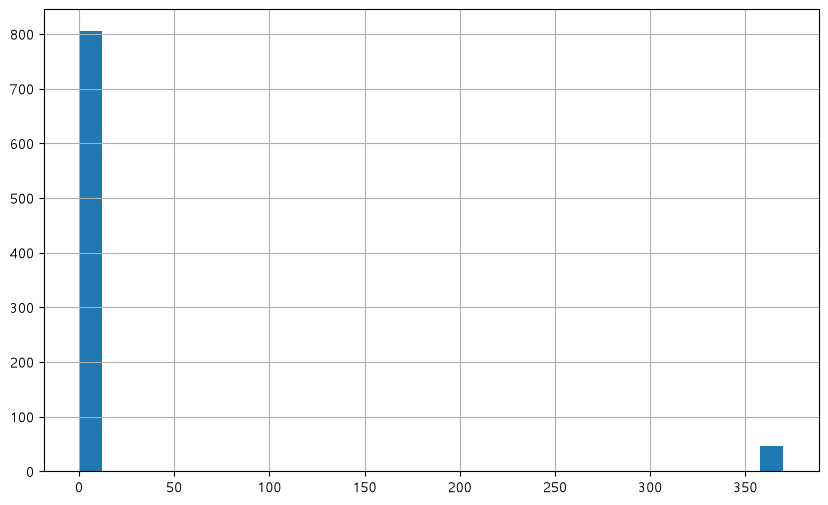

In [7]:
#homework1
dates = ["shipping_date", "delivery_date"]
ok = df[~df["date_error"]]
for col in dates:
    ok[col] = pd.to_datetime(ok[col])

date_diff = (ok["shipping_date"] - ok["delivery_date"]).abs().dt.days

date_diff.hist(bins=30, figsize=(10, 6))
    
date_diff_mean_median = (ok["shipping_date"] - ok["delivery_date"]).abs().agg(["mean", "median"])
print(date_diff_mean_median)
plt.show()

In [8]:
big = date_diff[date_diff > 300]
print(big.describe())
normal = date_diff[date_diff <= 300]
print("덩어리 제외 평균 :", round(normal.mean(), 2), " 중앙값 :", normal.median())

count     47.000000
mean     366.638298
std        1.798859
min      364.000000
25%      365.000000
50%      367.000000
75%      368.000000
max      370.000000
dtype: float64
덩어리 제외 평균 : 1.93  중앙값 : 2.0


**Q1 답**

- 배송 기간(date_error 가 아닌 줄)은 평균 22.05일, 중앙값 2일로 크게 다르다. 히스토그램 오른쪽 끝에 364~370일인 줄이 47건 몰려 있어 평균만 끌어올렸기 때문이다.
- 47건이 모두 약 365일 차이라 도착일 연도를 잘못 입력한 것으로 보고 배송 기간 계산에서 제외했다. 제외하면 평균 1.93일로 중앙값 2일과 거의 같아지므로, 보통 배송 기간은 약 2일이다.

satisfaction
1.0     7.589286
2.0    11.956522
3.0     7.812500
4.0     8.720930
5.0     6.930693
Name: is_returned, dtype: float64


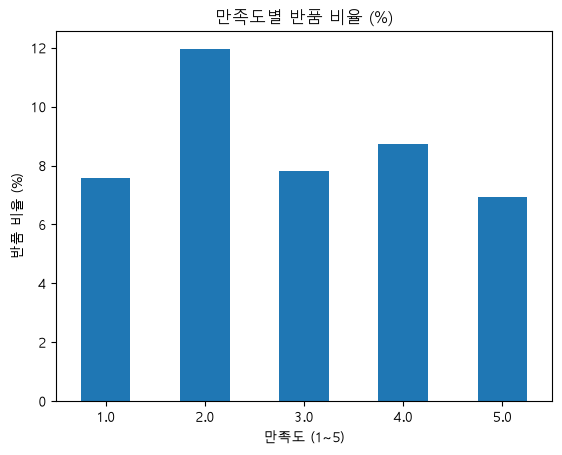

In [9]:
#homework
# 1. 반품 여부를 나타내는 불리언(True/False) 조건 추가
df["is_returned"] = df["status"] == "반품"

# 2. 만족도(satisfaction) 별 반품 비율(평균) 계산 (%)
return_rate = df.groupby("satisfaction")["is_returned"].mean() * 100

# 3. 결과 출력
print(return_rate)

# 4. 만족도별 반품 비율 막대그래프 시각화
import matplotlib.pyplot as plt

return_rate.plot.bar(rot=0, title="만족도별 반품 비율 (%)")
plt.xlabel("만족도 (1~5)")
plt.ylabel("반품 비율 (%)")
plt.show()

**Q2 답**

- 아니다. 만족도 1→5 순서로 반품 비율은 7.6% / 12.0% / 7.8% / 8.7% / 6.9% 로, 만족도가 낮을수록 반품이 많아지는 경향이 없다.
- 만족도 4(8.7%)가 만족도 1(7.6%)보다 오히려 높고, 가장 높은 것은 만족도 2(12.0%)이며 1과 5의 차이도 0.7%p 에 불과하다.

In [10]:
#by_category = df.groupby('category')[["quantity", "unit_price"]].agg(['sum', 'mean'])
#print(by_category)

cat_analysis = df.groupby("category").agg(
    order_count=("total_sales", "count"),   # 주문 건수
    total_sales=("total_sales", "sum"),     # 총매출
    avg_price=("unit_price", "mean"),       # 평균 단가
    avg_qty=("quantity", "mean")            # 평균 수량
)

# 금액 단위 정리 및 소수점 반올림하여 출력
cat_analysis["total_sales_억"] = (cat_analysis["total_sales"] / 1e8).round(2)
print(cat_analysis.round(1))

          order_count   total_sales  avg_price  avg_qty  total_sales_억
category                                                              
가구                213  2.843337e+09   257322.9     51.0           28.4
도서                204  2.453240e+09   238500.6     49.5           24.5
식품                210  2.513274e+09   255232.9     47.3           25.1
의류                170  2.181904e+09   249447.2     51.6           21.8
전자제품              207  2.471628e+09   249651.6     48.0           24.7


**Q3 답**

- 매출 1위는 가구(28.4억)로 건수 213건 · 평균 단가 257,323원 · 평균 수량 51.0개 모두 상위권이다. 2위 식품(25.1억)과 비교하면 건수(213 vs 210)와 단가(257,323 vs 255,233원)는 거의 같고 평균 수량(51.0 vs 47.3개, +7.8%)에서 가장 크게 차이 난다.
- 따라서 가구 1위는 어느 한 칸이 압도적이어서가 아니라 세 칸이 고루 높은 결과이고, 2위와의 차이를 만든 칸은 수량이다. 5위 의류(21.8억)는 단가 · 수량이 가구와 비슷하지만 건수가 170건으로 가장 적다.